In [1]:
pip install tensorflow

In [6]:
import tensorflow as tf

In [7]:
tf.__version__

'2.21.0'

In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, InputLayer

In [5]:
model = Sequential()
model.add(InputLayer(input_shape=(15,)))   # i/p =15 neurons
model.add(Dense(10, activation='relu'))    # 1st hidden layer
model.add(Dense(9, activation='relu'))     # 2nd hidden layer
model.add(Dense(5, activation='relu'))     # 3rd hidden layer
model.add(Dense(1, activation='sigmoid'))  # output layer

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315 (1.23 KB)

 Trainable params: 315 (1.23 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(loss = 'binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [9]:
import pandas as pd

In [10]:
chd = pd.read_csv("/content/framingham.csv")
chd.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [11]:
chd.isna().sum()

,0
male,0
age,0
education,105
currentSmoker,0
cigsPerDay,29
BPMeds,53
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,50


In [12]:
chd.dropna(axis=0, inplace=True)
chd.isna().sum()

,0
male,0
age,0
education,0
currentSmoker,0
cigsPerDay,0
BPMeds,0
prevalentStroke,0
prevalentHyp,0
diabetes,0
totChol,0


In [13]:
chd.shape

(3656, 16)

In [14]:
chd.duplicated().sum()

np.int64(0)

In [15]:
# Define X, Y
y = chd['TenYearCHD']
x = chd.drop(columns='TenYearCHD')

In [16]:
# Standardization
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_int = scaler.fit_transform(x)

In [17]:
x = pd.DataFrame(x_int, index=x.index, columns=x.columns)

In [19]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315 (1.23 KB)

 Trainable params: 315 (1.23 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.fit(x=x_train, y=y_train, epochs=50, validation_data=(x_test, y_test))

Epoch 1/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8454 - loss: 0.4746 - val_accuracy: 0.8566 - val_loss: 0.4211
Epoch 2/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4243 - val_accuracy: 0.8566 - val_loss: 0.4008
Epoch 3/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8454 - loss: 0.4096 - val_accuracy: 0.8566 - val_loss: 0.3894
Epoch 4/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8454 - loss: 0.4018 - val_accuracy: 0.8566 - val_loss: 0.3837
Epoch 5/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8454 - loss: 0.3970 - val_accuracy: 0.8566 - val_loss: 0.3798
Epoch 6/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8454 - loss: 0.3935 - val_accuracy: 0.8566 - val_loss: 0.3771
Epoch 7/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8454 - loss: 0.3911 - val_accuracy: 0.8566 - val_loss: 0.3749
Epoch 8/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8454 - loss: 0.3890 - val_accuracy: 0.8566 - val_loss:

<Axes: >

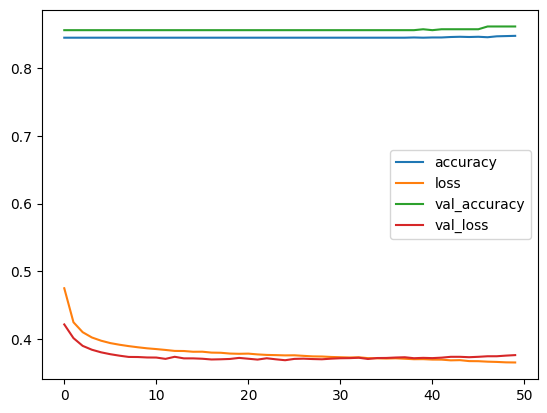

In [21]:
model_loss = pd.DataFrame(model.history.history)
model_loss.plot()

In [24]:
# Early stopping - stop training at minimum val_loss/testing_error/val_error
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', mode='min', patience=15)

In [25]:
model.fit(x=x_train, y=y_train, epochs=100,
          validation_data=(x_test, y_test), callbacks=[early_stop])

Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8529 - loss: 0.3613 - val_accuracy: 0.8593 - val_loss: 0.3751
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8536 - loss: 0.3613 - val_accuracy: 0.8593 - val_loss: 0.3758
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8540 - loss: 0.3609 - val_accuracy: 0.8593 - val_loss: 0.3764
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8526 - loss: 0.3599 - val_accuracy: 0.8566 - val_loss: 0.3770
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8516 - loss: 0.3597 - val_accuracy: 0.8552 - val_loss: 0.3761
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8540 - loss: 0.3597 - val_accuracy: 0.8566 - val_loss: 0.3768
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8536 - loss: 0.3590 - val_accuracy: 0.8470 - val_loss: 0.3787
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8553 - loss: 0.3585 - val_accuracy: 0.8525 - v

In [1]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import InputLayer, Dense, Dropout

In [2]:
model1 = Sequential()
model1.add(InputLayer(input_shape=(15,))) # 15 input features
model1.add(Dense(10, activation='relu'))  # 1st Hidden
model1.add(Dropout(0.2))                  # 20% of neurons in 1st Hidden layer - dropped
model1.add(Dense(9, activation='relu'))   # 2nd Hidden
model1.add(Dropout(0.2))                  # 20% of neurons in 2nd Hidden layer - dropped
model1.add(Dense(5, activation='relu'))   # 3rd Hidden
model1.add(Dropout(0.2))                  # 20% of neurons in 3rd Hidden layer - dropped
model1.add(Dense(1, activation='sigmoid')) # output layer

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


In [3]:
model1.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [4]:
model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 315 (1.23 KB)

 Trainable params: 315 (1.23 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='val_loss', mode='min', patience=10)

In [20]:
model1.fit(x=x_train, y=y_train, epochs=50, validation_data=(x_test, y_test),
           callbacks=[early_stop])

Epoch 1/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7302 - loss: 0.6058 - val_accuracy: 0.8566 - val_loss: 0.4890
Epoch 2/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8410 - loss: 0.5061 - val_accuracy: 0.8566 - val_loss: 0.4312
Epoch 3/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8451 - loss: 0.4716 - val_accuracy: 0.8566 - val_loss: 0.4145
Epoch 4/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4613 - val_accuracy: 0.8566 - val_loss: 0.4051
Epoch 5/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4442 - val_accuracy: 0.8566 - val_loss: 0.4006
Epoch 6/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4346 - val_accuracy: 0.8566 - val_loss: 0.3968
Epoch 7/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4277 - val_accuracy: 0.8566 - val_loss: 0.3941
Epoch 8/50
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8454 - loss: 0.4234 - val_accuracy: 0.8566 - val_loss:

<Axes: >

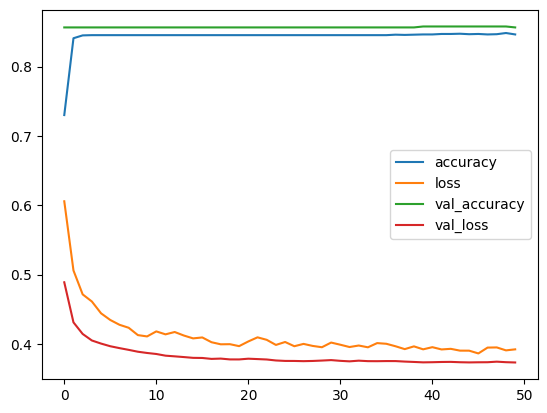

In [21]:
model_loss = pd.DataFrame(model1.history.history)
model_loss.plot()

In [23]:
score = model1.evaluate(x_test, y_test)

23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8566 - loss: 0.3734 


In [24]:
from keras.models import load_model
model1.save('CHD_model.h5')           ## saving of the model

In [25]:
# load the modelk
new_var = tf.keras.models.load_model('CHD_model.h5')

In [26]:
new_var.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │            99 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 5)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 317 (1.24 KB)

 Trainable params: 315 (1.23 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)